# SVM phân loại mức độ nguy hiểm của động vật

Bài toán sử dụng các triệu chứng và tên động vật để dự đoán nhãn `Dangerous`. Vì các thuộc tính đầu vào là dạng phân loại, notebook mã hóa chúng bằng OneHotEncoder và huấn luyện SVM với kernel RBF.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay)

DATA_PATH = Path("../data/animal.csv")
df = pd.read_csv(DATA_PATH)
print(f"Kích thước dữ liệu: {df.shape}")
display(df.head())
print("\nKiểu dữ liệu và giá trị thiếu:")
display(pd.DataFrame({"kiểu dữ liệu": df.dtypes.astype(str), "giá trị thiếu": df.isna().sum()}))


Kích thước dữ liệu: (871, 7)


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes



Kiểu dữ liệu và giá trị thiếu:


,kiểu dữ liệu,giá trị thiếu
AnimalName,str,0
symptoms1,str,0
symptoms2,str,0
symptoms3,str,0
symptoms4,str,0
symptoms5,str,0
Dangerous,str,2


## Khám phá nhãn và chuẩn bị dữ liệu

Các thuộc tính đầu vào được xử lý thiếu và mã hóa bên trong pipeline để tránh rò rỉ dữ liệu giữa tập huấn luyện và kiểm tra.

In [3]:
TARGET = "Dangerous"
print("Phân bố nhãn:")
display(df[TARGET].value_counts(dropna=False).to_frame("số lượng"))
df_model = df.dropna(subset=[TARGET]).copy()
X = df_model.drop(columns=[TARGET]).astype("string")
y = df_model[TARGET].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)


Phân bố nhãn:


,số lượng
Dangerous,
Yes,849
No,20
NaN,2


Train: (695, 6) Test: (174, 6)


## Huấn luyện SVM

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
categorical_features = X.columns.tolist()
preprocessor = ColumnTransformer([("categorical", Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ("scale", StandardScaler(with_mean=False)),
]), categorical_features)])
model = Pipeline([("preprocess", preprocessor), ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"))])
model.fit(X_train, y_train)
print("Số mẫu huấn luyện:", len(X_train))


Số mẫu huấn luyện: 695


## Đánh giá mô hình

Dữ liệu kiểm tra được giữ riêng khỏi quá trình huấn luyện. Báo cáo precision, recall, F1 và ma trận nhầm lẫn cho từng lớp.

Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



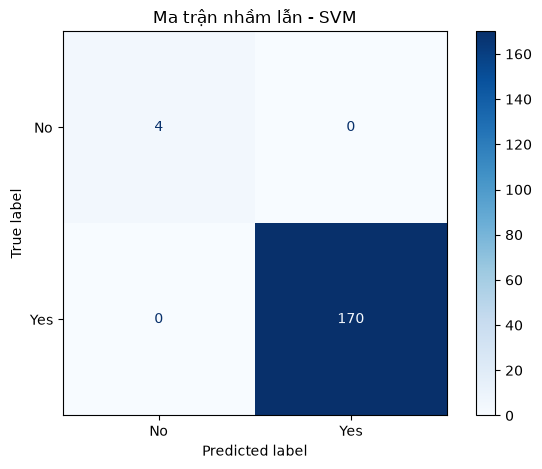

In [5]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn - SVM")
plt.tight_layout()
plt.show()


## Nhận xét

Dựa trên classification report và ma trận nhầm lẫn ở trên, hãy nhận xét mô hình phân loại **Dangerous** tốt đến đâu, đặc biệt chú ý lớp ít xuất hiện và các trường hợp dự đoán sai.